# code_063 · Sequence windows and irregular observations

**Book:** section 13.2. A self-contained structure-preserving input laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_13_GUIDE.md), [run evidence](../CHAPTER_13_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_063).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1363;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1363


<a id="windows"></a>
## Context and forecast intervals have different roles

Generate one irregular sensor record series around integer seconds 0–60; remove selected observations and delay a few arrivals. Values are signed acceleration in mm/s². Each cutoff c has context (c-5,c] and target interval (c,c+2]. Target is the mean of actual recorded values in that future interval, resolved at c+3; a complete label requires at least one target record and all its reports by resolution. It is a future recorded-mean target, not recovery of an unobserved continuous process.

Use stride one second. Training cutoffs 8–24 and final cutoffs 32–50 leave a gap so raw context/target records do not overlap. The deliberately invalid alternating-window split reuses raw records across roles. This is one construction fixture, not a training run or an assertion that gaps alone fix arbitrary temporal dependence.


In [2]:
base=np.arange(61,dtype=float);event=base+rng.uniform(-.15,.15,61);keep=~np.isin(base,[13,14,39]);event=event[keep];value=np.sin(.4*event)+rng.normal(0,.02,len(event));arrival=event+.15;arrival[np.arange(len(event))%11==0]+=1.8;record=np.arange(len(event));value[5]=0.
assert np.all(np.diff(event)>0) and np.all(arrival>=event)
def window(c):
 context=(event>c-5)&(event<=c)&(arrival<=c);target=(event>c)&(event<=c+2);resolved=bool(target.any() and np.all(arrival[target]<=c+3))
 return {'cutoff':float(c),'context_ids':record[context].tolist(),'target_ids':record[target].tolist(),'target_recorded_mean':float(value[target].mean()) if resolved else None,'resolution':float(c+3),'resolved':resolved}
train=[window(c) for c in range(8,25)];final=[window(c) for c in range(32,51)]
def raw_ids(windows):return set(j for w in windows for j in w['context_ids']+w['target_ids'])
assert not raw_ids(train)&raw_ids(final)
all_windows=[window(c) for c in range(8,51)];overlap=raw_ids(all_windows[::2])&raw_ids(all_windows[1::2]);assert len(overlap)>0
for w in train+final:
 assert all(event[j]<=w['cutoff'] and arrival[j]<=w['cutoff'] for j in w['context_ids'])
 assert all(w['cutoff']<event[j]<=w['cutoff']+2 for j in w['target_ids'])
RESULTS['window_counts']={'train':len(train),'final':len(final),'invalid_alternating_raw_overlap':len(overlap),'unresolved_train':sum(not w['resolved'] for w in train),'unresolved_final':sum(not w['resolved'] for w in final)};RESULTS['separated_raw_records']=True


<a id="resampling"></a>
## Resampling cannot interpolate from an unavailable future endpoint

For a five-point regular grid ending at c, use the most recent observation at or before each grid time that had arrived by that grid time; hold it for at most 1.5 seconds. Otherwise output a placeholder zero plus mask=false. This conservative replay rule is stricter than admitting all records that arrived by c, and is chosen explicitly. The valid observed zero is not missing. Padding variable-length context arrays similarly requires a mask; a zero placeholder alone loses the distinction. Linear interpolation using a later observation would change the admitted information.


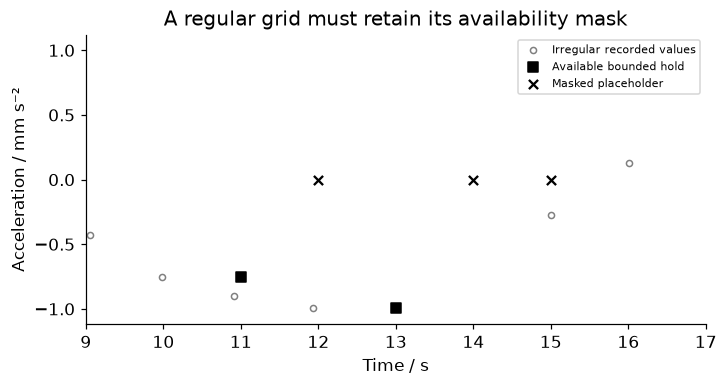

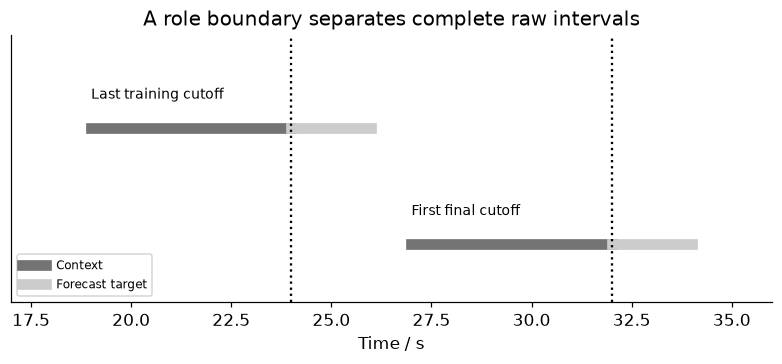

In [3]:
def replay_grid(c):
 grid=np.arange(c-4,c+1,dtype=float);out=np.zeros(5);mask=np.zeros(5,dtype=bool);source=np.full(5,-1,dtype=int)
 for k,s in enumerate(grid):
  ids=np.flatnonzero((event<=s)&(arrival<=s))
  if len(ids) and s-event[ids[-1]]<=1.5:source[k]=ids[-1];out[k]=value[ids[-1]];mask[k]=True
 return grid,out,mask,source
grid,out,mask,source=replay_grid(15)
assert all(event[j]<=s and arrival[j]<=s and s-event[j]<=1.5 for s,j,m in zip(grid,source,mask) if m)
# Future values are not read by the replay; perturb them and reconstruct.
saved=value.copy();value[event>15]=1e9;after=replay_grid(15);np.testing.assert_array_equal(after[1],out);np.testing.assert_array_equal(after[2],mask);value[:]=saved
assert value[5]==0. and np.isfinite(value[5]);RESULTS['grid_at_15']={'times':grid.tolist(),'values':out.tolist(),'observed_mask':mask.tolist(),'source_ids':source.tolist()};RESULTS['future_value_perturbation_invariance']=True
fig,ax=plt.subplots(figsize=(6.5,3.4));ax.scatter(event,value,s=16,facecolors='white',edgecolors='.5',label='Irregular recorded values');ax.scatter(grid[mask],out[mask],marker='s',color='black',label='Available bounded hold');ax.scatter(grid[~mask],np.zeros(np.sum(~mask)),marker='x',color='black',label='Masked placeholder');ax.set(xlim=(9,17),xlabel='Time / s',ylabel='Acceleration / mm s⁻²',title='A regular grid must retain its availability mask');ax.legend(fontsize=7);plt.show()
fig,ax=plt.subplots(figsize=(7,3.2))
for y0,c,label in [(2,24,'Last training cutoff'),(1,32,'First final cutoff')]:
 ax.plot([c-5,c],[y0,y0],lw=7,color='.45');ax.plot([c,c+2],[y0,y0],lw=7,color='.8');ax.axvline(c,color='black',ls=':');ax.text(c-5,y0+.25,label,fontsize=9)
ax.plot([],[],lw=7,color='.45',label='Context');ax.plot([],[],lw=7,color='.8',label='Forecast target');ax.set(xlim=(17,36),ylim=(.5,2.8),yticks=[],xlabel='Time / s',title='A role boundary separates complete raw intervals');ax.legend(fontsize=8,loc='lower left');plt.show()


In [4]:
summary={'example_id':'code_063','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['context forecast stride and raw-record overlap', 'event and arrival aligned windows', 'bounded forward hold and masks', 'future-invariant construction and label maturity'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["context forecast stride and raw-record overlap", "event and arrival aligned windows", "bounded forward hold and masks", "future-invariant construction and label maturity"], "elapsed_seconds": 0.133, "example_id": "code_063", "hardware": "Darwin arm64 CPU", "results": {"future_value_perturbation_invariance": true, "grid_at_15": {"observed_mask": [true, false, true, false, false], "source_ids": [10, -1, 12, -1, -1], "times": [11.0, 12.0, 13.0, 14.0, 15.0], "values": [-0.7505928372855579, 0.0, -0.9922499357853239, 0.0, 0.0]}, "separated_raw_records": true, "window_counts": {"final": 19, "invalid_alternating_raw_overlap": 44, "train": 17, "unresolved_final": 3, "unresolved_train": 4}}, "seed": 1363, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
